# Predicting a building's thermal indicators from an 8-hour test

**coEnergy assessment — executable report.** From 8 hours of indoor air temperature `Tint(t)`
and injected heating power `U(t)`, predict six intrinsic thermal indicators of a building, using
1,000,000 dynamic thermal simulations of `quentin_house`.

| Family | Indicator | Unit | Meaning |
|---|---|---|---|
| HLC | `HLC` | W/K | global heat loss coefficient |
| Hb | `HLC_mit`, `HLC_ext` | W/K | losses to adjoining spaces / to the outside, `HLC = HLC_mit + HLC_ext` |
| CDT | `tau_b`, `tau_n`, `tau_inf` | h | time constants: structural discharge, persistence of night cooling (8 h), mean residence time |

## Summary

* **Approach.** One multi-output network (dilated TCN + attention pooling, 186k parameters) reads
  the raw temperature rise and heater state and predicts the indicators; `HLC = HLC_mit + HLC_ext`
  holds exactly by construction. Frozen, stratified 80/10/10 split; the test split was scored
  once, at the end.
* **Results (test split, 100k simulations).** `HLC` within **8.3 %** on average (95 % of the
  buildings within 21 %), `HLC_ext` 9.7 %, `HLC_mit` 15.8 %, time constants 12–18 %; validation
  and test agree to the second decimal. The slow time constants are barely better than the
  population mean (R² ≈ 0.1).
* **Why it stops there.** Every architecture plateaus at the same loss because the data does:
  under heating, different buildings produce the same curve. An 8 h test measures one
  combination almost perfectly, the **effective heat capacity `C_n = HLC × tau_n`** (R² 0.84),
  and much less how it splits into losses and inertia.
* **Uncertainty.** A variance head plus conformal calibration gives intervals with a guaranteed
  95 % coverage (about ±20 % on `HLC`).
* **Protocol.** Always heat; heat 55–65 % of the time with on/off steps of 1.3–4 h; test longer
  than 8 h when `HLC` and the time constants matter. This agrees with the paper behind the
  assessment, which we extend from `HLC` to six indicators.

## Contents

1. [The problem seen through physics](#1.-The-problem-seen-through-physics)
2. [The data: what the 1M simulations really contain](#2.-The-data:-what-the-1M-simulations-really-contain)
3. [Methodological choices, and why](#3.-Methodological-choices,-and-why)
4. [What we tried and what we learned](#4.-What-we-tried-and-what-we-learned)
5. [Final results](#5.-Final-results)
6. [Why the models plateau: an identifiability limit](#6.-Why-the-models-plateau:-an-identifiability-limit)
7. [Uncertainty: honest, calibrated intervals](#7.-Uncertainty:-honest,-calibrated-intervals)
8. [The best excitation, and the paper](#8.-The-best-excitation,-and-the-paper)
9. [Limits and next steps](#9.-Limits-and-next-steps)

Each section summarises a detailed notebook (`01`–`07`); every number below is recomputed here
from the data and the trained models (about 5 minutes on a GPU, once the runs exist: see the
README).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

from ipe_prediction.data import TARGET_NAMES
from ipe_prediction.eda import identifiability as I
from ipe_prediction.eda import plotting as P
from ipe_prediction.training.config import DataConfig
from ipe_prediction.training.dataset import ThermalDataset, make_dataloader, prepare_data
from ipe_prediction.training.engine import amp_dtype, evaluate, load_model
from ipe_prediction.training.metrics import per_family_metrics

P.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
torch.manual_seed(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUNS = ROOT / "outputs" / "runs"

tensors, split = prepare_data(DataConfig())
dT, U, Y6 = tensors.delta_t, tensors.heater_on, tensors.targets
hours = np.arange(dT.shape[1]) / 60
print(f"{len(Y6):,} simulations x {dT.shape[1]} steps (1 min) | split sizes:", {k: len(v) for k, v in split.items()})

1,000,000 simulations x 480 steps (1 min) | split sizes: {'train': 800002, 'val': 99999, 'test': 99999}


## 1. The problem seen through physics

A building seen from its indoor air behaves, to first order, like a set of thermal capacities
linked by conductances. With a single lumped node,

$$C\,\frac{dT}{dt} = U(t) - H\,\big(T - T_{\text{bound}}\big),$$

the response to heating has a gain `1/H` (the heat loss coefficient) and a time constant
`tau = C / H`. A real building has several nodes (air, light partitions, heavy walls), hence
several time constants, and two boundaries (outside, adjoining spaces), hence `HLC_ext` and
`HLC_mit`.

Three consequences guide the whole study:

* **Heating is needed to see `HLC`**: without injected power, the curve is a free relaxation that
  does not reveal the gain.
* **Slow phenomena are hard to see in 8 h**: `tau_b` is about 50 h on average, `tau_inf` 31 h;
  the test only shows the beginning of these relaxations.
* **The initial state is unknown**: the walls are not at equilibrium with the air at `t = 0`
  (the simulator randomises it), so part of each curve is a free relaxation unrelated to the
  heating.

### Context: the method behind the assessment

The assessment builds on Nassif, Guernouti, Stabat & Cohen, *Building-specific excitation
optimization and simulation-driven* HLC identification (SSRN preprint
[6928008](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=6928008)). Instead of fitting an
RC model to one measurement, they:

1. build a detailed thermal model of the building and draw a **population** of variants
   (thermophysical parameters within ±60 %), each with an exact `HLC`;
2. simulate their response to **random excitations** (sine or PRBS) from **random initial
   states**, with sensor noise;
3. train a CNN-GRU to map the curve to `HLC`, and use it to **choose the excitation** that
   minimises the error (k-NN surrogate of the RMSE + Bayesian optimisation);
4. apply that excitation on site and read the measured curve with a test-specific model.

On the HAMEX test cell they recover `HLC` within 2 W/K of a 14-day co-heating reference in 6 to
24 hours. Their method predicts `HLC` only and lists other indicators as future work: this
assessment is that extension, on a dataset built the same way (one house, a population of
variants, PRBS excitations, random initial states).

## 2. The data: what the 1M simulations really contain

Details: `01_eda`, `03_target_structure`, `06_advanced_eda`, `07_data_quality`.

,unit,mean,std,min,5%,50%,95%,max
HLC,W/K,232.926,31.329,111.403,183.237,231.800,286.371,367.995
HLC_mit,W/K,120.488,26.256,42.843,80.176,118.900,166.248,231.533
HLC_ext,W/K,112.438,17.112,52.646,84.742,112.188,141.041,185.892
tau_b,h,50.001,10.097,20.199,35.638,48.819,68.363,122.885
tau_n,h,11.039,2.009,5.172,8.213,10.791,14.718,25.839
tau_inf,h,31.231,7.530,10.485,20.864,30.199,45.101,93.119


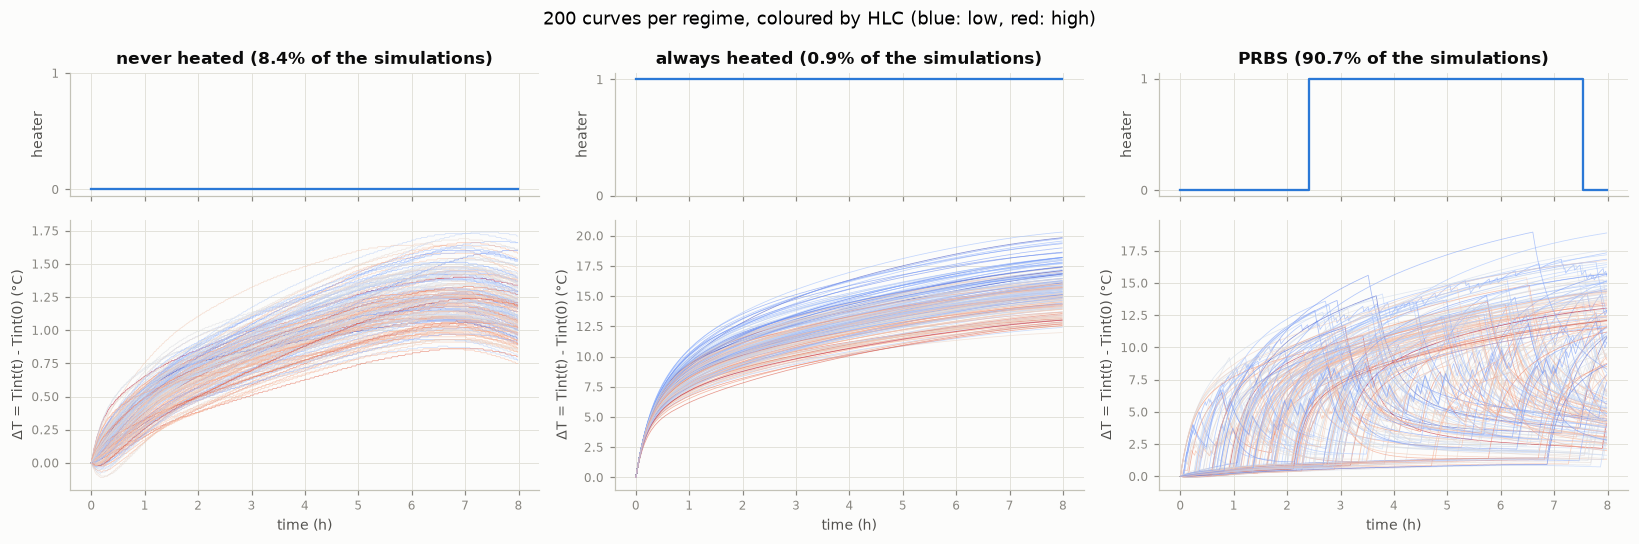

In [2]:
duty = torch.cat([u.float().mean(1) for u in U.split(200_000)])
regime = np.select([duty.numpy() == 0, duty.numpy() == 1], ["never heated", "always heated"], "PRBS")
fig, axes = plt.subplots(2, 3, figsize=(15, 5), sharex=True, gridspec_kw={"height_ratios": [1, 2.2]})
for col, r in enumerate(["never heated", "always heated", "PRBS"]):
    idx = np.flatnonzero(regime == r)[:200]
    hlc = Y6[idx, 0].numpy()
    colours = plt.cm.coolwarm((hlc - hlc.min()) / np.ptp(hlc))
    axes[0, col].step(hours, U[idx[0]].numpy(), where="post")
    axes[0, col].set(title=f"{r} ({(regime == r).mean():.1%} of the simulations)", yticks=[0, 1], ylabel="heater")
    for i, c in zip(idx, colours):
        axes[1, col].plot(hours, dT[i].numpy(), color=c, lw=0.5, alpha=0.6)
    axes[1, col].set(xlabel="time (h)", ylabel="ΔT = Tint(t) - Tint(0) (°C)")
fig.suptitle("200 curves per regime, coloured by HLC (blue: low, red: high)")
fig.tight_layout()

desc = pd.DataFrame(Y6.numpy(), columns=TARGET_NAMES).describe(percentiles=[0.05, 0.5, 0.95]).T
desc.insert(0, "unit", ["W/K"] * 3 + ["h"] * 3)
display(desc[["unit", "mean", "std", "min", "5%", "50%", "95%", "max"]])

In [3]:
group, size = I.input_groups(U)
print(f"distinct heating sequences: {len(size):,} for {len(group):,} simulations "
      f"(PRBS seed always {int(tensors.excitation_column('prbs_seed')[0])})")
print(f"share of simulations whose exact input is shared by >= 1000 others: {size[group].ge(1000).float().mean():.0%}")

distinct heating sequences: 2,798 for 1,000,000 simulations (PRBS seed always 42)
share of simulations whose exact input is shared by >= 1000 others: 65%


**What matters in the data.**

* **Clean simulation output** (`07_data_quality`): no missing value, `U` is exactly 0 or 7 kW,
  every simulation starts from the same air temperature, the targets satisfy
  `HLC = HLC_mit + HLC_ext` and `tau_n <= tau_inf <= tau_b` everywhere, no broken curve, no
  outlier, no contradictory duplicate. **No cleaning is needed**, and removing "uninformative"
  simulations does not help (section 4).
* **One heating family**: every test is a full-power PRBS (pseudo-random on/off sequence) whose
  only varying settings are the minimum and maximum step durations and the probability of being
  on. With a single generator seed, they produce only **2,798 distinct sequences**: many
  simulations received exactly the same input. This is used below as a controlled experiment.
* **No repeated building** (`03_target_structure`): every target vector is unique. The five
  independent targets (`HLC` is a sum) are five quantities, but the three time constants mostly
  move together (`tau_b` and `tau_inf` are 95 % predictable from the other taus) and are
  negatively correlated with the heat losses (`tau ~ C / H`).
* **Resolution**: temperatures are rounded to 0.01 °C; without heating, 72 % of the 1-min
  increments are exactly zero, so slopes must be read over tens of minutes, not per minute.

## 3. Methodological choices, and why

| Choice | Alternatives considered | Reason |
|---|---|---|
| Inputs `ΔT(t) = Tint(t) - Tint(0)` and the heater state (0/1), 480 steps | absolute temperature, power in W, hand-made features | all simulations start at the same `Tint(0)` and `U` is binary 0 / 7 kW: nothing is lost, and both channels have a natural scale; extra physics channels (time, cumulative heat, integral of the rise) gave no gain |
| Split 80/10/10 over the 1M simulations, **stratified** on excitation regime × duty cycle × switching speed and on HLC quartile, frozen on disk | random split | every split contains every kind of test and of building in the same proportions; the test split is evaluated **once**, at the end |
| Targets: heat losses standardised in W/K, time constants in **log** then standardised | raw values | puts W/K and hours on the same footing; the time constants are right-skewed |
| The network predicts `HLC_mit`, `HLC_ext` and the taus; **`HLC = HLC_mit + HLC_ext`** is computed | predicting HLC freely | the additivity constraint stated by the assessment holds exactly by construction, at no cost (the best prediction of a sum is the sum of the best predictions) |
| Loss: **MSE in the standardised space**, equal weights | per-target weights, Huber | simulated targets have no outliers; all six indicators count equally |
| Model: **dilated residual TCN + attention pooling** (186k parameters) | CNN-GRU, residual CNN + GRU ("Model A"), hybrid with system-identification features | all reach the same level (section 4); the TCN processes the 480 steps in parallel (fast, memory linear in time), sees the whole 8 h window (receptive field 509 steps), and the pooling learns which parts of the test matter |
| AdamW, warmup 1 epoch then **cosine decay** 1e-3 → 1e-5, batch 512, bf16, gradient clipping | constant learning rate, step schedule, SGD | the decay lets the weights settle; SGD is far slower on this problem |
| **Precise BatchNorm** before each validation: running statistics recomputed over 100 training batches, weights frozen | default moving-average statistics | the tests mix curves of very different amplitude (≈1 °C unheated, ≈15 °C always heated): the moving-average statistics depend on the last batches seen and made the validation loss jump by up to 0.7 from one epoch to the next, even with a learning rate of 1e-5 (section 5); recomputing them removes this noise and makes the choice of the best epoch meaningful |
| Metrics per indicator and per family: MAPE, **P95 of the absolute percentage error**, R² | MSE only | interpretable in physical units; P95 is the criterion of the SSRN paper behind this assessment |

## 4. What we tried and what we learned

| Experiment | Result (standardised MSE on validation, lower is better) | Lesson |
|---|---|---|
| Architectures: CNN-GRU, Model A (residual CNN + GRU), TCN + attention, small and large | all plateau at the same level for the same budget (e.g. 0.81 vs 0.80 for TCNs of 53k and 186k parameters on 200k samples) | the limit is not the architecture |
| Can the models overfit 1,024 samples? (cell below) | real labels are learned **barely faster than shuffled labels**, while a label computed from the curve is learned in a few epochs by every model | the pipeline is fine; the real labels are only partly determined by the curve |
| Hybrid: TCN + 20 system-identification features (per-sample Laguerre and ARX least squares) | 0.821 vs 0.811 for the TCN alone; features alone 0.858 (branch `sysid-hybrid`) | the network already extracts at least what a linear identification gives |
| Training only on the informative tests (high duty cycle, long steps, 31 % of the data) | 0.710 vs 0.708 for the full model on those same tests (`05_informative_subset`) | removing data does not remove noise: the model already adapts to the test it sees |
| Mean + variance outputs (β-NLL) | same accuracy as MSE, plus calibrated uncertainties (section 7) | kept for the intervals |
| Unstable validation loss (jumps even at a learning rate of 1e-5) | diagnosed as noise in the BatchNorm running statistics; recomputing them exactly turned a final checkpoint scored 0.834 into 0.732 | fixed in the pipeline (precise BN before each validation) |
| Full training set, 30 epochs, cosine schedule, precise BN | final model, section 5 | more data, a decaying learning rate and exact BatchNorm statistics are what improved the score |

In [4]:
# Overfitting check on 1,024 training samples: plain MLP, three labels (fast, about 1 min)
idx = split["train"][torch.randperm(len(split["train"]))[:1024]]
x = torch.cat([dT[idx][:, ::4] / dT.std(), U[idx][:, ::4].float()], 1).to(dev)
labels = {
    "real HLC_mit": Y6[idx, 1],
    "shuffled HLC_mit (pure noise)": Y6[idx, 1][torch.randperm(1024)],
    "label computed from the curve": (dT[idx][:, -60:].mean(1) + 1).log() * (1 + U[idx].float().mean(1)),
}
fits = {}
for name, t in labels.items():
    t = ((t - t.mean()) / t.std()).to(dev)
    torch.manual_seed(0)
    mlp = nn.Sequential(nn.Linear(240, 512), nn.ReLU(), nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 1)).to(dev)
    opt = torch.optim.Adam(mlp.parameters(), 1e-3)
    for ep in range(1, 201):
        for b in torch.randperm(1024, device=dev).split(128):
            loss = (mlp(x[b])[:, 0] - t[b]).pow(2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        if ep in (10, 50, 200):
            with torch.no_grad():
                fits.setdefault(name, {})[f"epoch {ep}"] = (mlp(x)[:, 0] - t).pow(2).mean().item()
display(pd.DataFrame(fits).T.round(4).rename_axis("training MSE"))

,epoch 10,epoch 50,epoch 200
training MSE,,,
real HLC_mit,0.748,5.386e-01,3.369e-01
shuffled HLC_mit (pure noise),0.954,7.618e-01,4.993e-01
label computed from the curve,0.003,6.000e-04,3.000e-04


## 5. Final results

Final model `final_tcn_mse`: TCN + attention trained on the 800k training simulations for 30
epochs, with precise BatchNorm. Below: the learning curves (compared with the same model trained
with the default BatchNorm statistics), then the metrics on the **whole validation split**
(100k simulations) and on the **test split** (100k simulations, scored once, after every choice
was made on validation).

validation standardised MSE: 0.734


,unit,MAE,RMSE,bias,P95_AE,MAPE_%,P95_APE_%,R2
HLC,W/K,18.996,23.830,0.431,46.738,8.325,20.967,0.419
HLC_mit,W/K,18.055,22.447,0.144,43.778,15.880,42.368,0.265
HLC_ext,W/K,10.453,13.071,0.287,25.495,9.588,24.177,0.416
tau_b,h,7.393,9.521,-0.949,18.582,14.874,36.616,0.114
tau_n,h,1.357,1.744,-0.160,3.415,12.220,29.649,0.244
tau_inf,h,5.547,7.215,-0.842,14.199,17.938,44.112,0.085


,MAPE_%,P95_APE_%,R2
HLC,8.325,20.967,0.419
Hb,12.734,33.273,0.341
CDT,15.010,36.792,0.147


TEST split (scored once): standardised MSE 0.731


validation                     test                 
            MAPE_% P95_APE_%     R2  MAPE_% P95_APE_%     R2
HLC          8.325    20.967  0.419   8.315    20.890  0.424
HLC_mit     15.880    42.368  0.265  15.818    41.846  0.270
HLC_ext      9.588    24.177  0.416   9.667    24.485  0.415
tau_b       14.874    36.616  0.114  14.834    36.344  0.114
tau_n       12.220    29.649  0.244  12.212    29.585  0.250
tau_inf     17.938    44.112  0.085  17.914    44.010  0.086

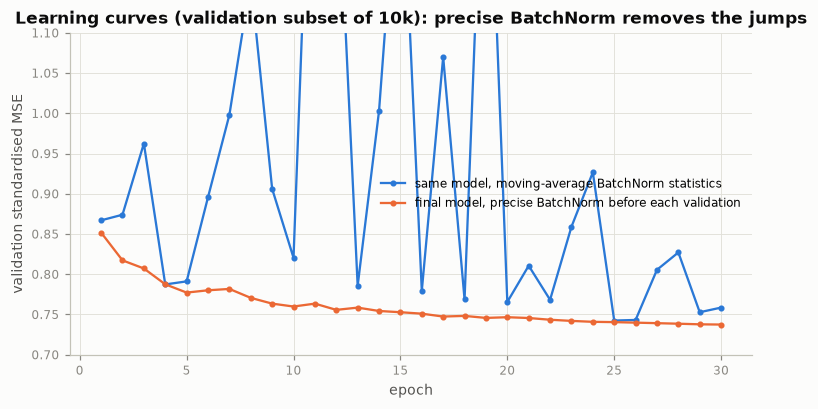

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for run, label in [("final_tcn_mse_v1", "same model, moving-average BatchNorm statistics"),
                   ("final_tcn_mse", "final model, precise BatchNorm before each validation")]:
    h = pd.read_csv(RUNS / run / "history.csv")
    ax.plot(h["epoch"], h["val_loss"], marker=".", label=label)
ax.set(xlabel="epoch", ylabel="validation standardised MSE", ylim=(0.7, 1.1),
       title="Learning curves (validation subset of 10k): precise BatchNorm removes the jumps")
ax.legend()

def predict(run):
    model, prep, cfg = load_model(RUNS / run, device=str(dev))
    loader = make_dataloader(ThermalDataset(tensors, split["val"]), 4096)
    return evaluate(model, prep, loader, dev, amp_dtype(dev, cfg.train.amp), cfg.train.loss), prep

res, prep = predict("final_tcn_mse")
print(f"validation standardised MSE: {res['loss']:.3f}")
display(res["metrics"].round(3))
display(per_family_metrics(res["metrics"]).round(3))

test_metrics = RUNS / "final_tcn_mse" / "metrics_test.csv"
if test_metrics.exists():
    test = pd.read_csv(test_metrics, index_col=0)
    test_loss = json.loads((RUNS / "final_tcn_mse" / "summary_test.json").read_text())["loss"]
    print(f"TEST split (scored once): standardised MSE {test_loss:.3f}")
    cols = ["MAPE_%", "P95_APE_%", "R2"]
    display(pd.concat({"validation": res["metrics"][cols], "test": test[cols]}, axis=1).round(3))
else:
    print("Test split not evaluated yet: uv run ipe-evaluate --run outputs/runs/final_tcn_mse --split test")

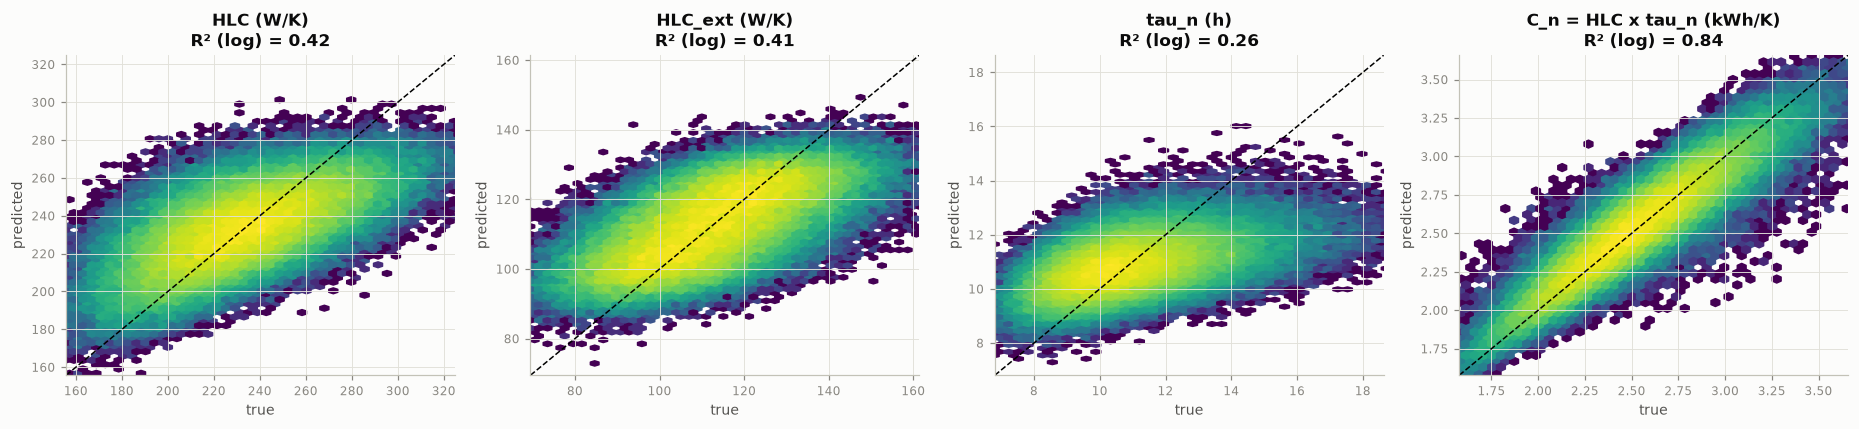

In [6]:
pred, true = res["pred"], res["target"]
show = {
    "HLC (W/K)": (true[:, 0], pred[:, 0]),
    "HLC_ext (W/K)": (true[:, 2], pred[:, 2]),
    "tau_n (h)": (true[:, 4], pred[:, 4]),
    "C_n = HLC x tau_n (kWh/K)": (true[:, 0] * true[:, 4] / 1000, pred[:, 0] * pred[:, 4] / 1000),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (name, (t, p)) in zip(axes, show.items()):
    ax.hexbin(t.numpy(), p.numpy(), gridsize=60, bins="log", mincnt=1, cmap="viridis")
    lim = [float(t.quantile(0.002)), float(t.quantile(0.998))]
    ax.plot(lim, lim, "k--", lw=1)
    r2 = 1 - ((p.log() - t.log()) ** 2).mean() / t.log().var()
    ax.set(xlim=lim, ylim=lim, xlabel="true", ylabel="predicted", title=f"{name}\nR² (log) = {r2:.2f}")
fig.tight_layout()

**Reading.** `HLC` is predicted within 8.3 % on average (95 % of the buildings within about
21 %), `HLC_ext` within 9.7 %. `HLC_mit` and the time constants are much less determined;
`tau_b` and `tau_inf` are barely better than the population average (R² ≈ 0.1). Validation and
test give the same numbers (standardised MSE 0.734 and 0.731): the model choices made on
validation did not overfit it. The physical constraints hold on every prediction: all values
positive, `HLC = HLC_mit + HLC_ext` to 2e-5 W/K, `tau_n <= tau_inf <= tau_b` in 100 % of the
cases. In contrast with the time constants, the product `C_n = HLC x tau_n`, an **effective heat
capacity**, is predicted with R² ≈ 0.84: the predictions lie along a direction the test measures
well, and spread along one it does not.

## 6. Why the models plateau: an identifiability limit

Details: `06_advanced_eda` (model-free) and `04_identifiability_uncertainty` (with the model).

Simulations that received **exactly the same input** form a controlled experiment: their
curves differ only because of the building and of the hidden initial state.

* **The building explains the heated curves almost entirely**: with the input fixed, the
  targets explain 94 % of the variance of always-heated curves (and up to 98 % at the end of PRBS
  tests), but only 20 % of unheated ones. The hidden initial state is the main nuisance only for
  unheated tests.
* **Yet the targets cannot be read back from the curves**: the mapping from the building to the
  curve is many-to-one. For two simulations with the same input and the closest curves ("curve
  twins"), the targets differ almost as much as for two random simulations:

In [7]:
g_always = int(group[(duty == 1).nonzero()[0, 0]])  # the always-heated input
g_prbs = int(group[(duty > 0) & (duty < 1)].mode().values)  # the most frequent PRBS input
rows = {}
Yv = I.target_view(Y6)
for label, g in [("always heated", g_always), ("most frequent PRBS sequence", g_prbs)]:
    members = (group == g).nonzero().flatten()
    q, t = I.curve_twins(dT[members][:, ::5], n_query=3000)
    rnd = torch.randint(len(members), (len(q),))
    ratio = (Yv[members[q]] - Yv[members[t]]).abs().median(0).values / (Yv[members[q]] - Yv[members[rnd]]).abs().median(0).values
    rows[label] = pd.Series(ratio.numpy(), index=I.VIEW_NAMES)
display(pd.DataFrame(rows).T.round(2).rename_axis("median |Δ target| twins / random pairs (0 = determined, 1 = no information)"))

,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_n
"median |Δ target| twins / random pairs (0 = determined, 1 = no information)",,,,,,,
always heated,0.76,0.86,0.89,0.96,0.91,0.97,0.35
most frequent PRBS sequence,0.80,0.85,0.94,1.01,0.92,1.03,0.38


* **What the test measures**: canonical correlations between the representation learned by the
  network and the five independent targets are 0.97, 0.66, 0.52, 0.15 and 0.03. One combination
  is almost fully determined: `log HLC + log tau_n`, i.e. the **effective heat capacity
  `C_n = HLC x tau_n`** charged during the test. Two are partly determined, two not at all.
* **Consequence**: the test tells very well *how much heat the building stores over a few hours*,
  but much less how this splits into "loses heat fast" (`HLC`) and "responds slowly" (`tau`).
  Errors on `HLC` and `tau_n` are therefore anti-correlated. The model is at the information
  limit: its scores match the model-free bounds of `06_advanced_eda` (HLC R² 0.42 vs ≈ 0.38–0.51,
  `C_n` 0.84 vs ≈ 0.86), which is why no architecture change moved the plateau.
* **A longer test would help** `HLC`, `HLC_ext` and `tau_n` (their information is still rising
  at 8 h), not `C_n` (saturated after 2–3 h).

## 7. Uncertainty: honest, calibrated intervals

Since part of each indicator is not determined by the test, a point prediction must come with an
interval. The β-NLL model predicts a standard deviation per indicator; **split conformal
prediction** rescales it so that the interval `prediction ± q σ` has 95 % coverage on new data
(calibrated on half of the validation split, checked on the other half).

In [8]:
res_nll, prep_nll = predict("final_tcn_gaussian_nll")
yz = torch.where(prep_nll.log.cpu(), res_nll["pred"].log(), res_nll["pred"])
z_pred = (yz - prep_nll.mean.cpu()) / prep_nll.std.cpu()
z_true = prep_nll.cpu().encode(tensors.targets[split["val"]])
sigma = res_nll["pred_std_z"]
half = torch.rand(len(z_pred), generator=torch.Generator().manual_seed(0)) < 0.5
ratio = (z_pred - z_true).abs() / sigma
rows = {}
for j, n in enumerate(TARGET_NAMES):
    q = torch.quantile(ratio[half, j], 0.95)
    lo = prep_nll.cpu().from_standardized(z_pred - q * sigma)[~half, j]
    hi = prep_nll.cpu().from_standardized(z_pred + q * sigma)[~half, j]
    tr = prep_nll.cpu().from_standardized(z_true)[~half, j]
    rows[n] = {"raw ±1.96σ coverage": float((ratio[:, j] <= 1.96).double().mean()),
               "conformal 95 % coverage (held-out)": float(((tr >= lo) & (tr <= hi)).double().mean()),
               "median interval width": float((hi - lo).median()), "unit": "W/K" if n.startswith("HLC") else "h"}
print(f"β-NLL model, validation standardised MSE of the means: {res_nll['loss']:.3f}")
display(pd.DataFrame(rows).T)

β-NLL model, validation standardised MSE of the means: 0.734


,raw ±1.96σ coverage,conformal 95 % coverage (held-out),median interval width,unit
HLC,0.966,0.95,92.441,W/K
HLC_mit,0.944,0.949,86.946,W/K
HLC_ext,0.948,0.948,50.585,W/K
tau_b,0.951,0.95,36.102,h
tau_n,0.952,0.95,6.549,h
tau_inf,0.951,0.95,27.097,h


**Reading.** The predicted uncertainties are already well calibrated, and conformal calibration
guarantees the 95 % coverage. The intervals are wide where the test carries little information:
about ±20 % on `HLC`, several tens of hours on `tau_b`. The predicted σ varies little from one
test to another (its correlation with the actual error is weak): the uncertainty comes mostly from
what an 8 h test cannot see, for every test.

## 8. The best excitation, and the paper

The assessment aims at *optimising coEnergy's measurement protocols*. The final model's error on
`HLC`, grouped by the settings of the heating sequence, tells which tests are the most
informative (details: `04_identifiability_uncertainty`; model-free information per protocol and
per test duration: `06_advanced_eda`).

,mean,count
regime,,
always heated,7.70,871
never heated,9.67,8417
on/off (PRBS),8.21,90711


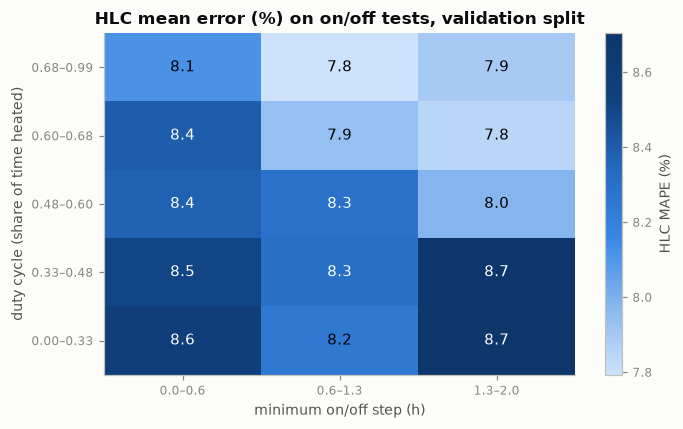

In [9]:
idx_val = res["index"]
ape = ((res["pred"][:, 0] - res["target"][:, 0]).abs() / res["target"][:, 0] * 100).numpy()
d_val = duty[idx_val].numpy()
t_min = tensors.excitation_column("prbs_min_duration_hours")[idx_val].numpy()
reg = np.select([d_val == 0, d_val == 1], ["never heated", "always heated"], "on/off (PRBS)")
display(pd.DataFrame({"regime": reg, "HLC MAPE %": ape}).groupby("regime")["HLC MAPE %"]
        .agg(["mean", "count"]).round(2))

on_off = reg == "on/off (PRBS)"
grid = pd.DataFrame({
    "duty cycle": pd.qcut(d_val[on_off], 5),
    "minimum on/off step (h)": pd.qcut(t_min[on_off], 3),
    "ape": ape[on_off],
}).pivot_table(index="duty cycle", columns="minimum on/off step (h)", values="ape",
               aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(grid.values[::-1], cmap=P.SEQUENTIAL, aspect="auto")
ax.set_xticks(range(grid.shape[1]), [f"{max(c.left, 0):.1f}–{c.right:.1f}" for c in grid.columns])
ax.set_yticks(range(grid.shape[0]), [f"{i.left:.2f}–{i.right:.2f}" for i in grid.index[::-1]])
ax.set(xlabel="minimum on/off step (h)", ylabel="duty cycle (share of time heated)",
       title="HLC mean error (%) on on/off tests, validation split")
ax.grid(False)
for (r, k), v in np.ndenumerate(grid.values[::-1]):
    ax.text(k, r, f"{v:.1f}", ha="center", va="center", color="white" if v > grid.values.mean() else "black")
fig.colorbar(im, ax=ax, label="HLC MAPE (%)")
fig.tight_layout()

**Reading and recommendations.**

* **Always heat.** Without heating, `HLC` is barely measurable: no injected energy, no
  heat-loss measurement. The model's error on `HLC` is 9.7 % on unheated tests vs 7.7 % when
  always heated, and the model-free information drops from R² 0.43 to 0.13 (`06`).
* **High duty cycle, long steps.** Among on/off tests, the error on `HLC` goes from 8.6–8.7 %
  with a low duty cycle to 7.8–7.9 % when the heater is on 60 % of the time or more with steps of
  at least 0.6 h: more energy and lower frequencies reach the walls. The effect is real but
  moderate; the model-free analysis (`06`) places the most informative protocols at 55–65 %
  heating with steps of 1.3–4 h, and fast switching (steps under about 40 min) as the worst.
* **Longer tests if `HLC` and the time constants matter.** On the most informative protocols,
  the information on `HLC`, `HLC_ext` and `tau_n` is still rising at 8 h, while the effective
  capacity `C_n` is fully measured after 2–3 h (`06`).
* **Report what the test measures well**: `C_n` together with the six indicators and their
  calibrated intervals.

**Relation with the paper.** The paper chooses the excitation of each test the same way in
spirit: a k-NN surrogate of the `HLC` error over the generator settings (power, switching
probability, minimum duration), minimised by Bayesian optimisation. Our analysis maps the error
and the information over the equivalent settings (duty cycle × minimum step) on 1M simulations,
for six indicators instead of one. Both agree that longer windows give more stable `HLC` (their
1,600 simulated campaigns, §3.4; our information-vs-duration curves), and both find the 95th
percentile of the error proportional to the RMSE (their Fig. 13; here P95 ≈ 2 × RMSE on `HLC`,
47 vs 24 W/K). What this work adds is the limit of an 8 h test beyond `HLC`: it identifies
`C_n`, not its split into losses and inertia.

![Best excitation and the paper](../docs/figures/08_paper.png)

## 9. Limits and next steps

* **New heating sequences.** Every validation and test input also appears in training (2,798
  sequences in total): the test score is a score on known protocols, for this one house. A split holding out whole
  heating sequences would measure generalisation to a new protocol.
* **Real measurements.** Simulated curves are noise-free apart from the 0.01 °C rounding, with an
  unknown but simulated initial state. Real tests add sensor noise and weather, which the SSRN
  paper handles by training on simulations of the actual test conditions (with added noise).
* **Physics-informed models.** A grey-box model predicting the parameters of an RC network *and*
  the initial wall temperatures, trained with a reconstruction loss, would separate the building
  from the hidden state explicitly; it cannot exceed the information limit, but would make the
  predictions physically interpretable.
* **Joint uncertainty.** Predicting `C_n` and `HLC` jointly (with `tau_n = C_n / HLC`) would give
  consistent intervals along the measured and the unmeasured directions.

**Reproducibility.** `uv sync`, then `uv run ipe-train --name final_tcn_mse` (defaults of
`config.py` = this model) and `uv run ipe-train --name final_tcn_gaussian_nll --loss gaussian_nll`,
`uv run ipe-evaluate --run outputs/runs/final_tcn_mse --split test` (once), then run this
notebook. The README lists every command and notebook, and summarises the project in 9 slides
(`scripts/make_readme_figures.py`).